<a href="https://colab.research.google.com/github/vesakhaa/Statistika_Semester_3/blob/main/Statistika_Jobsheet11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

CI 95% (n=100): (np.float64(9536751.780385412), np.float64(14309708.219614588))
Lebar CI: 4772956.439229175
CI 99% (n=30): (np.float64(4885878.383098378), np.float64(16657521.616901621))
Lebar CI 99%: 11771643.233803242


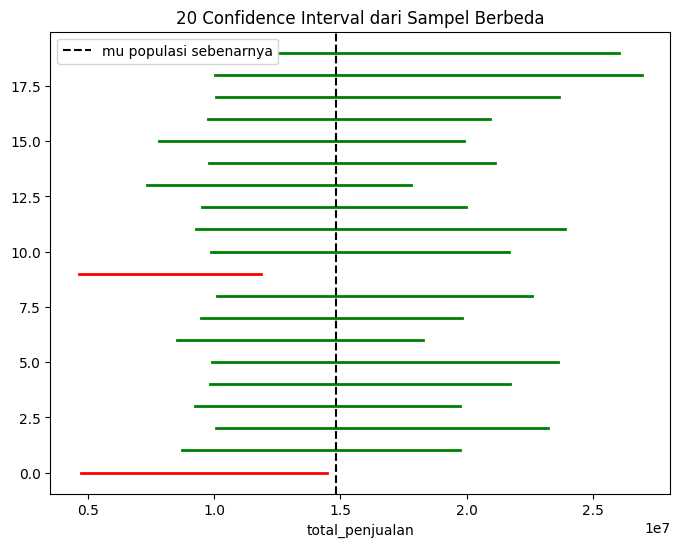

Rata-rata rating : 3.5333
CI 95% rating    : (np.float64(3.1322), np.float64(3.9345))
Lebar CI         : 0.8023
Rata-rata Surabaya (n=50): 11673800.0
CI 95% Surabaya          : (np.float64(8132547.2185546085), np.float64(15215052.781445391))
Lebar CI Surabaya        : 7082505.562890783
CI 90% (n=30)  : (np.float64(7143485.761450935), np.float64(14399914.238549063))
Lebar CI 90%   : 7256428.477098128


In [9]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

df = pd.read_csv('transaksi_elektronikprima.csv')
df.head()

# sampel30 = df['total_penjualan'].sample(30, random_state=42)
# mean30 = sampel30.mean()
# sem30  = sampel30.std(ddof=1) / np.sqrt(len(sampel30))

# ci30 = stats.t.interval(confidence=0.95, df=len(sampel30)-1,
#                          loc=mean30, scale=sem30)
# print('Rata-rata:', mean30)
# print('CI 95%:', ci30)
# print('Lebar CI:', ci30[1] - ci30[0])

sampel100 = df['total_penjualan'].sample(100, random_state=42)
mean100 = sampel100.mean()
sem100  = sampel100.std(ddof=1) / np.sqrt(len(sampel100))

ci100 = stats.t.interval(confidence=0.95, df=len(sampel100)-1,
                          loc=mean100, scale=sem100)
print('CI 95% (n=100):', ci100)
print('Lebar CI:', ci100[1] - ci100[0])

ci30_99 = stats.t.interval(confidence=0.99, df=len(sampel30)-1,
                            loc=mean30, scale=sem30)
print('CI 99% (n=30):', ci30_99)
print('Lebar CI 99%:', ci30_99[1] - ci30_99[0])

mu_populasi = df['total_penjualan'].mean()  # dihitung dari SELURUH data

plt.figure(figsize=(8,6))
for i in range(20):
    s = df['total_penjualan'].sample(30, random_state=i)
    sem = s.std(ddof=1) / np.sqrt(30)
    lo, hi = stats.t.interval(confidence=0.95, df=29,
                               loc=s.mean(), scale=sem)
    warna = 'green' if lo <= mu_populasi <= hi else 'red'
    plt.plot([lo, hi], [i, i], color=warna, linewidth=2)

plt.axvline(mu_populasi, color='black', linestyle='--',
            label='mu populasi sebenarnya')
plt.legend()
plt.xlabel('total_penjualan')
plt.title('20 Confidence Interval dari Sampel Berbeda')
plt.show()

#Latihan Mandiri

# Bersihkan missing value dan ambil sampel n=30
rating_valid = df['rating_kepuasan'].dropna()
sampel_r30 = rating_valid.sample(30, random_state=42)

mean_r30 = sampel_r30.mean()
sem_r30  = sampel_r30.std(ddof=1) / np.sqrt(len(sampel_r30))

ci_r30 = stats.t.interval(confidence=0.95, df=len(sampel_r30)-1,
                          loc=mean_r30, scale=sem_r30)

print('Rata-rata rating :', round(mean_r30, 4))
print('CI 95% rating    :', (round(ci_r30[0], 4), round(ci_r30[1], 4)))
print('Lebar CI         :', round(ci_r30[1] - ci_r30[0], 4))

# Filter khusus cabang Surabaya lalu ambil sampel n=50
df_sby = df[df['cabang'] == 'Surabaya']
sampel_sby50 = df_sby['total_penjualan'].sample(50, random_state=42)

mean_sby50 = sampel_sby50.mean()
sem_sby50  = sampel_sby50.std(ddof=1) / np.sqrt(len(sampel_sby50))

ci_sby50 = stats.t.interval(confidence=0.95, df=len(sampel_sby50)-1,
                            loc=mean_sby50, scale=sem_sby50)

print('Rata-rata Surabaya (n=50):', mean_sby50)
print('CI 95% Surabaya          :', ci_sby50)
print('Lebar CI Surabaya        :', ci_sby50[1] - ci_sby50[0])

# Hitung CI 90% menggunakan sampel30 dari Langkah 1
ci30_90 = stats.t.interval(confidence=0.90, df=len(sampel30)-1,
                           loc=mean30, scale=sem30)

print('CI 90% (n=30)  :', ci30_90)
print('Lebar CI 90%   :', ci30_90[1] - ci30_90[0])